In [ ]:
import os
import copy
import torch
import numpy as np
import matplotlib.pyplot as plt
from transformers import WhisperForConditionalGeneration, WhisperProcessor

In [ ]:
try:
  from google.colab import drive
  drive.mount('/content/drive')
  SAVE_DIR = "/content/drive/MyDrive/Distil_Whisper_Vi_Yanshee/models/distil_phowhisper_base_init"
except ImportError:
  SAVE_DIR = "./distil_phowhisper_base_init"

Mounted at /content/drive


In [ ]:
os.makedirs(SAVE_DIR,exist_ok=True)
decive = "cude" if torch.cuda.is_available() else "cpu"
print(f"Dang chay:{decive.upper()}")
if decive == "cuda":
  print(f"Tên GPU: {torch.cuda.get_device_name(0)}")

Dang chay:CPU


In [ ]:
# Chuẩn bắt buộc của whisper
SAMPLE_RATE = 16000
# Thử tạo 1 đoạn âm thanh dài 3.0
DURATION_SEC = 3.0
# Tạo thử 1 sóng âm (Waveform) dài 3 giây (tổng cộng 3 * 16000 = 48,000 con số)
# Kết hợp âm trầm 220Hz và âm cao 880Hz (mô phỏng âm thanh biến thiên)
t = np.linspace(0, DURATION_SEC, int(SAMPLE_RATE * DURATION_SEC), endpoint=False)
waveform = 0.5 * np.sin(2 * np.pi * 220 * t) + 0.3 * np.sin(2 * np.pi * 880 * t)
waveform = waveform.astype(np.float32)

In [ ]:
print(f"\n[1] Kích thước Waveform (3 giây @ 16kHz): {waveform.shape} mẫu số thực")


[1] Kích thước Waveform (3 giây @ 16kHz): (48000,) mẫu số thực


In [ ]:
# Tải bộ xử lý (Processor = FeatureExtractor + Tokenizer) của PhoWhisper-base
MODEL_ID = "vinai/PhoWhisper-base"
processor = WhisperProcessor.from_pretrained(MODEL_ID)

preprocessor_config.json:   0%|          | 0.00/339 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/1.32k [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/804 [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/836k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/2.20M [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/494k [00:00<?, ?B/s]

normalizer.json:   0%|          | 0.00/52.7k [00:00<?, ?B/s]

added_tokens.json:   0%|          | 0.00/2.08k [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/2.08k [00:00<?, ?B/s]

In [ ]:
# Biến đổi Waveform -> Log-Mel Spectrogram chuẩn của Whisper
# Lưu ý: Whisper tự động chèn thêm khoảng lặng (padding) cho đủ 30 giây = 3000 cột!
inputs = processor(waveform, sampling_rate=SAMPLE_RATE, return_tensors="pt")
log_mel = inputs.input_features  # Tensor kích thước: [batch_size, 80, 3000]
print(f"[2] Kích thước Log-Mel Spectrogram sau khi qua WhisperProcessor: {tuple(log_mel.shape)}")
print("    -> Giải thích: (Batch=1, 80 dải tần Mel, 3000 khung thời gian ứng với 30 giây)")

[2] Kích thước Log-Mel Spectrogram sau khi qua WhisperProcessor: (1, 80, 3000)
    -> Giải thích: (Batch=1, 80 dải tần Mel, 3000 khung thời gian ứng với 30 giây)


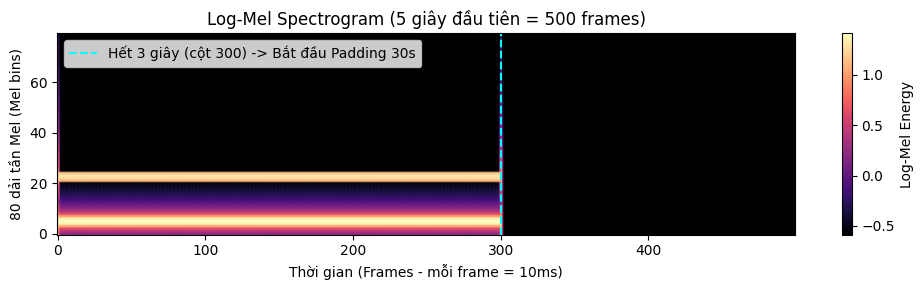

In [ ]:
# Vẽ thử 300 khung thời gian đầu tiên (tương ứng 3 giây có âm thanh) và phần sau (padding 0)
plt.figure(figsize=(10, 3))
plt.imshow(log_mel[0, :, :500].numpy(), aspect="auto", origin="lower", cmap="magma")
plt.colorbar(label="Log-Mel Energy")
plt.axvline(x=300, color="cyan", linestyle="--", label="Hết 3 giây (cột 300) -> Bắt đầu Padding 30s")
plt.title("Log-Mel Spectrogram (5 giây đầu tiên = 500 frames)")
plt.xlabel("Thời gian (Frames - mỗi frame = 10ms)")
plt.ylabel("80 dải tần Mel (Mel bins)")
plt.legend()
plt.tight_layout()
plt.show()

In [ ]:
import os
import copy
import torch
import numpy as np
import matplotlib.pyplot as plt
from transformers import WhisperForConditionalGeneration, WhisperProcessor

# 1. KHAI BÁO THIẾT BỊ & THƯ MỤC LƯU TRÊN GOOGLE DRIVE
device = "cuda" if torch.cuda.is_available() else "cpu"
print(f"🖥️ Đang chạy trên thiết bị: {device.upper()}")

try:
    from google.colab import drive
    drive.mount('/content/drive')
    SAVE_DIR = "/content/drive/MyDrive/Distil_Whisper_Vi_Yanshee/models/distil_phowhisper_base_init"
except ImportError:
    SAVE_DIR = "./distil_phowhisper_base_init"

os.makedirs(SAVE_DIR, exist_ok=True)

# 2. TẠO SÓNG ÂM 16kHz -> LOG-MEL SPECTROGRAM (80, 3000)
SAMPLE_RATE = 16000  # 16,000 mẫu / giây
DURATION_SEC = 3.0   # 3 giây âm thanh

t = np.linspace(0, DURATION_SEC, int(SAMPLE_RATE * DURATION_SEC), endpoint=False)
waveform = (0.5 * np.sin(2 * np.pi * 220 * t) + 0.3 * np.sin(2 * np.pi * 880 * t)).astype(np.float32)
print(f"\n[1] Kích thước Waveform (3 giây @ 16kHz): {waveform.shape}")

MODEL_ID = "vinai/PhoWhisper-base"
processor = WhisperProcessor.from_pretrained(MODEL_ID)

inputs = processor(waveform, sampling_rate=SAMPLE_RATE, return_tensors="pt")
log_mel = inputs.input_features
print(f"[2] Kích thước Log-Mel Spectrogram: {tuple(log_mel.shape)}")

# 3. CẮT GIẢM DECODER CÒN 2 LỚP THEO CHUẨN DISTIL-WHISPER
print(f"\n[3] Đang tải mô hình gốc {MODEL_ID} để cắt giảm Decoder...")
teacher_or_base = WhisperForConditionalGeneration.from_pretrained(MODEL_ID)

orig_enc_layers = teacher_or_base.config.encoder_layers
orig_dec_layers = teacher_or_base.config.decoder_layers
orig_params = sum(p.numel() for p in teacher_or_base.parameters()) / 1e6

STUDENT_DEC_LAYERS = 2
student_config = copy.deepcopy(teacher_or_base.config)
student_config.decoder_layers = STUDENT_DEC_LAYERS

student_model = WhisperForConditionalGeneration(student_config)
student_model.load_state_dict(teacher_or_base.state_dict(), strict=False)

# Copy lớp đầu tiên (0) và lớp cuối cùng (orig_dec_layers - 1)
layers_to_copy = np.linspace(0, orig_dec_layers - 1, STUDENT_DEC_LAYERS, dtype=int)
print(f"    -> Đang copy các lớp Decoder thứ {layers_to_copy.tolist()} (từ tổng {orig_dec_layers} lớp) sang Student...")

for student_idx, teacher_idx in enumerate(layers_to_copy):
    student_model.model.decoder.layers[student_idx].load_state_dict(
        teacher_or_base.model.decoder.layers[teacher_idx].state_dict()
    )

student_params = sum(p.numel() for p in student_model.parameters()) / 1e6
print(f"✅ ĐÃ TẠO XONG STUDENT KHỞI TẠO!")
print(f"   - Mô hình gốc ({MODEL_ID}): {orig_enc_layers} Enc / {orig_dec_layers} Dec | {orig_params:.1f}M tham số")
print(f"   - Mô hình Student rút gọn : {student_config.encoder_layers} Enc / {student_config.decoder_layers} Dec | {student_params:.1f}M tham số (Giảm {(1 - student_params/orig_params)*100:.1f}%)")

# 4. SMOKE_TEST CHẠY THỬ & LƯU VÀO DRIVE
student_model.to(device)
with torch.no_grad():
    generated_ids = student_model.generate(log_mel.to(device), max_new_tokens=10)
    transcription = processor.batch_decode(generated_ids, skip_special_tokens=True)[0]
print(f"\n[4] SMOKE_TEST chạy thử Student (trên sóng âm nhân tạo): '{transcription}'")

student_model.save_pretrained(SAVE_DIR)
processor.save_pretrained(SAVE_DIR)
print(f"💾 Đã lưu Student Model & Processor vào:\n   {SAVE_DIR}")

🖥️ Đang chạy trên thiết bị: CPU
Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).

[1] Kích thước Waveform (3 giây @ 16kHz): (48000,)
[2] Kích thước Log-Mel Spectrogram: (1, 80, 3000)

[3] Đang tải mô hình gốc vinai/PhoWhisper-base để cắt giảm Decoder...


Loading weights:   0%|          | 0/246 [00:00<?, ?it/s]

[transformers] Passing `generation_config` together with generation-related arguments=({'begin_suppress_tokens', 'suppress_tokens'}) is deprecated and will be removed in future versions. Please pass either a `generation_config` object OR all generation parameters explicitly, but not both.


    -> Đang copy các lớp Decoder thứ [0, 5] (từ tổng 6 lớp) sang Student...
✅ ĐÃ TẠO XONG STUDENT KHỞI TẠO!
   - Mô hình gốc (vinai/PhoWhisper-base): 6 Enc / 6 Dec | 72.6M tham số
   - Mô hình Student rút gọn : 6 Enc / 2 Dec | 55.8M tham số (Giảm 23.2%)


[transformers] Both `max_new_tokens` (=10) and `max_length`(=20) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
[transformers] Ignoring clean_up_tokenization_spaces=True for BPE tokenizer WhisperTokenizer. The clean_up_tokenization post-processing step is designed for WordPiece tokenizers and is destructive for BPE (it strips spaces before punctuation). Set clean_up_tokenization_spaces=False to suppress this warning, or set clean_up_tokenization_spaces_for_bpe_even_though_it_will_corrupt_output=True to force cleanup anyway.



[4] SMOKE_TEST chạy thử Student (trên sóng âm nhân tạo): ' g g g g g g g g g g'


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

💾 Đã lưu Student Model & Processor vào:
   /content/drive/MyDrive/Distil_Whisper_Vi_Yanshee/models/distil_phowhisper_base_init


In [ ]:
import os
import time
import copy
import subprocess
import sys
import torch
from IPython.display import Audio, display
from transformers import WhisperForConditionalGeneration, WhisperProcessor

# Tự động cài đặt gtts và librosa nếu chưa có
subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", "gtts", "librosa"])
from gtts import gTTS
import librosa

device = "cuda" if torch.cuda.is_available() else "cpu"
SAVE_DIR = "/content/drive/MyDrive/Distil_Whisper_Vi_Yanshee/models/distil_phowhisper_base_init"

# 1. TẠO MẪU ÂM THANH TIẾNG VIỆT THẬT (CÂU LỆNH ROBOT YANSHEE)
ground_truth = "Yanshee ơi hãy tiến lên phía trước hai bước rồi rẽ trái"
tts = gTTS(text=ground_truth, lang="vi")
tts.save("test_vi.mp3")
audio_array, sr = librosa.load("test_vi.mp3", sr=16000)

print(f"📝 Văn bản gốc (Ground Truth): '{ground_truth}'")
print(f"🎵 Thông số âm thanh: dài {len(audio_array)/sr:.2f} giây | Tần số lấy mẫu: {sr} Hz")
display(Audio(audio_array, rate=sr))

# 2. TẢI MODEL GỐC (PhoWhisper-base) & ĐO THỜI GIAN ENCODER - DECODER
MODEL_ID = "vinai/PhoWhisper-base"
processor = WhisperProcessor.from_pretrained(MODEL_ID)
model_orig = WhisperForConditionalGeneration.from_pretrained(MODEL_ID).to(device)
model_orig.eval()

input_features = processor(audio_array, sampling_rate=16000, return_tensors="pt").input_features.to(device)

with torch.no_grad():
    # BƯỚC A: Chạy riêng ENCODER (Chỉ chạy đúng 1 lần)
    t0 = time.time()
    encoder_outputs = model_orig.model.encoder(input_features)
    enc_time = (time.time() - t0) * 1000
    print(f"\n[A] ENCODER chạy 1 lần mất: {enc_time:.1f} ms")
    print(f"    -> Đầu vào Log-Mel : {tuple(input_features.shape)}")
    print(f"    -> Đầu ra Hidden H : {tuple(encoder_outputs.last_hidden_state.shape)} (3000 cột nén còn 1500 cột!)")

    # BƯỚC B: Chạy DECODER sinh từng Token
    t1 = time.time()
    predicted_ids = model_orig.generate(input_features, language="vi", task="transcribe")
    total_time = (time.time() - t1) * 1000

tokens = processor.tokenizer.convert_ids_to_tokens(predicted_ids[0])
text_pred = processor.batch_decode(predicted_ids, skip_special_tokens=True)[0]

print(f"\n[B] CÁC TOKEN DECODER SINH RA (Tổng {len(predicted_ids[0])} tokens):")
for idx, (tid, tok) in enumerate(zip(predicted_ids[0].tolist(), tokens)):
    decoded_piece = processor.tokenizer.decode([tid])
    print(f"    Bước {idx:02d}: ID={tid:<6} | Token={tok:<22} | Chữ='{decoded_piece}'")

# 3. ĐỐI CHIẾU VỚI STUDENT (2 LỚP DECODER) ĐÃ LƯU Ở CHẶNG 1
student_init = WhisperForConditionalGeneration.from_pretrained(SAVE_DIR).to(device)
# Sửa lỗi generation_config: copy bảng ngôn ngữ chuẩn từ model_orig sang student_init và lưu lại
student_init.generation_config = copy.deepcopy(model_orig.generation_config)
student_init.save_pretrained(SAVE_DIR)
student_init.eval()

with torch.no_grad():
    stu_ids = student_init.generate(input_features, language="vi", task="transcribe", max_new_tokens=25)
    stu_text = processor.batch_decode(stu_ids, skip_special_tokens=True)[0]

print("\n" + "=" * 70)
print(f"📝 CÂU GỐC (GROUND TRUTH)            : '{ground_truth}'")
print(f"✅ KẾT QUẢ GỐC (6 lớp Dec)           : '{text_pred}'")
print(f"⚠️ KẾT QUẢ STUDENT CHƯA TRAIN (2 lớp): '{stu_text}'")
print("=" * 70)

📝 Văn bản gốc (Ground Truth): 'Yanshee ơi hãy tiến lên phía trước hai bước rồi rẽ trái'
🎵 Thông số âm thanh: dài 4.73 giây | Tần số lấy mẫu: 16000 Hz


Loading weights:   0%|          | 0/246 [00:00<?, ?it/s]


[A] ENCODER chạy 1 lần mất: 1489.6 ms
    -> Đầu vào Log-Mel : (1, 80, 3000)
    -> Đầu ra Hidden H : (1, 1500, 512) (3000 cột nén còn 1500 cột!)

[B] CÁC TOKEN DECODER SINH RA (Tổng 25 tokens):
    Bước 00: ID=88     | Token=y                      | Chữ='y'
    Bước 01: ID=335    | Token=am                     | Chữ='am'
    Bước 02: ID=17531  | Token=sea                    | Chữ='sea'
    Bước 03: ID=43144  | Token=ĠÆ¡i                   | Chữ=' ơi'
    Bước 04: ID=276    | Token=Ġh                     | Chữ=' h'
    Bước 05: ID=49205  | Token=Ã£y                    | Chữ='ãy'
    Bước 06: ID=220    | Token=Ġ                      | Chữ=' '
    Bước 07: ID=7317   | Token=ti                     | Chữ='ti'
    Bước 08: ID=16240  | Token=áº¿n                   | Chữ='ến'
    Bước 09: ID=33368  | Token=ĠlÃªn                  | Chữ=' lên'
    Bước 10: ID=903    | Token=Ġph                    | Chữ=' ph'
    Bước 11: ID=2686   | Token=ÃŃa                    | Chữ='ía'
    Bước 12: ID=220  

Loading weights:   0%|          | 0/149 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

[transformers] Both `max_new_tokens` (=25) and `max_length`(=448) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)



📝 CÂU GỐC (GROUND TRUTH)            : 'Yanshee ơi hãy tiến lên phía trước hai bước rồi rẽ trái'
✅ KẾT QUẢ GỐC (6 lớp Dec)           : 'yamsea ơi hãy tiến lên phía trước hai bước rồi rẽ trái.'
⚠️ KẾT QUẢ STUDENT CHƯA TRAIN (2 lớp): 'nhnhnhnhnhnhnhnhnhnhnhnhnhnhnhnhnhnhnhnhnhnhnhnhnh'


In [ ]:
import re
import unicodedata

# Bảng chuyển số thành chữ tiếng Việt cơ bản (rất hay gặp trong lệnh Robot: "2 bước" vs "hai bước")
NUM_TO_VI = {
    "0": "không", "1": "một", "2": "hai", "3": "ba", "4": "bốn",
    "5": "năm", "6": "sáu", "7": "bảy", "8": "tám", "9": "chín", "10": "mười"
}

In [ ]:
def normalize_vi_text(text:str,replace_numbers:bool = True) -> str:
    """
    Chuẩn hóa văn bản tiếng Việt trước khi tính WER/CER:
    1. Chuẩn hóa bảng mã Unicode về NFC (tránh lỗi dấu tiếng Việt dựng sẵn vs tổ hợp).
    2. Chuyển toàn bộ về chữ thường (lowercase).
    3. Loại bỏ toàn bộ dấu câu (.,!?;:"'()-...).
    4. (Tùy chọn) Đổi các con số đơn lẻ (0-10) thành chữ tiếng Việt.
    5. Gộp nhiều khoảng trắng liên tiếp thành 1 khoảng trắng duy nhất.
    """
    # Buoc 1
    text = unicodedata.normalize("NFC",text)
    # Buoc 2
    text = text.lower()
    # Buoc 3
    text = re.sub(r"[^\w\s]"," ", text)
    # Bước 4: Đổi số thành chữ nếu bật replace_numbers
    if replace_numbers:
        words = text.split()
        words = [NUM_TO_VI.get(w, w) for w in words]
        text = " ".join(words)
    # Bước 5: Xóa khoảng trắng thừa ở 2 đầu và giữa các từ
    text = re.sub(r"\s+", " ", text).strip()
    return text

In [ ]:
def edit_distance_details(ref_tokens: list, hyp_tokens: list):
    """
    Tính số lỗi Substitution (S), Deletion (D), Insertion (I)
    giữa chuỗi gốc (ref) và chuỗi dự đoán (hyp) bằng Quy hoạch động.
    """
    n, m = len(ref_tokens), len(hyp_tokens)
    # dp[i][j] lưu (tổng_lỗi, S, D, I)
    dp = [[(0, 0, 0, 0) for _ in range(m + 1)] for _ in range(n + 1)]
    for i in range(1, n + 1):
        dp[i][0] = (i, 0, i, 0)  # Xóa i phần tử (Deletions)
    for j in range(1, m + 1):
        dp[0][j] = (j, 0, 0, j)  # Chèn j phần tử (Insertions)
    for i in range(1, n + 1):
        for j in range(1, m + 1):
            if ref_tokens[i - 1] == hyp_tokens[j - 1]:
                dp[i][j] = dp[i - 1][j - 1]
            else:
                # 1. Thay thế (Substitution)
                s_cost, s_S, s_D, s_I = dp[i - 1][j - 1]
                cand_sub = (s_cost + 1, s_S + 1, s_D, s_I)
                # 2. Xóa (Deletion - thiếu từ so với gốc)
                d_cost, d_S, d_D, d_I = dp[i - 1][j]
                cand_del = (d_cost + 1, d_S, d_D + 1, d_I)
                # 3. Chèn (Insertion - thừa từ so với gốc)
                i_cost, i_S, i_D, i_I = dp[i][j - 1]
                cand_ins = (i_cost + 1, i_S, i_D, i_I + 1)
                # Chọn phương án có tổng lỗi nhỏ nhất
                dp[i][j] = min([cand_sub, cand_del, cand_ins], key=lambda x: x[0])
    total_err, S, D, I = dp[n][m]
    rate = (total_err / n) * 100.0 if n > 0 else 0.0
    return {"rate_percent": rate, "S": S, "D": D, "I": I, "N": n}

In [ ]:
def compute_wer_cer(ground_truth: str, prediction: str, normalize: bool = True):
    if normalize:
        gt = normalize_vi_text(ground_truth)
        pred = normalize_vi_text(prediction)
    else:
        gt = ground_truth
        pred = prediction
    # WER: tách theo từng từ (cách nhau bởi khoảng trắng)
    wer_info = edit_distance_details(gt.split(), pred.split())
    # CER: tách theo từng ký tự (bỏ qua khoảng trắng hoặc giữ nguyên chuỗi)
    cer_info = edit_distance_details(list(gt), list(pred))
    return gt, pred, wer_info, cer_info

In [ ]:
gt_text = "Yanshee ơi hãy tiến lên phía trước 2 bước rồi rẽ trái"
pred_base = "yamsea ơi hãy tiến lên phía trước hai bước rồi rẽ trái."
pred_student_untrained = "nhnhnhnhnhnhnhnhnhnhnhnhnhnhnhnhnhnhnhnhnhnhnhnhnh"
# So sánh KHI CHƯA CHUẨN HÓA vs KHI ĐÃ CHUẨN HÓA cho PhoWhisper-base
_, _, wer_raw, _ = compute_wer_cer(gt_text, pred_base, normalize=False)
gt_norm, pred_norm, wer_clean, cer_clean = compute_wer_cer(gt_text, pred_base, normalize=True)
_, _, wer_stu, cer_stu = compute_wer_cer(gt_text, pred_student_untrained, normalize=True)

In [ ]:
print("=== 1. TÁC DỤNG CỦA CHUẨN HÓA TIẾNG VIỆT (NORMALIZATION) ===")
print(f"Câu gốc ban đầu : '{gt_text}'")
print(f"Dự đoán ban đầu : '{pred_base}'")
print(f"❌ WER khi CHƯA chuẩn hóa: {wer_raw['rate_percent']:.2f}% (Lỗi: S={wer_raw['S']}, D={wer_raw['D']}, I={wer_raw['I']} trên N={wer_raw['N']} từ)")
print("   -> Bị phạt oan ở: 'Yanshee'!='yamsea', '2'!='hai', và 'trái'!='trái.' (3/12 từ = 25%!)")
print(f"\nCâu gốc đã chuẩn hóa : '{gt_norm}'")
print(f"Dự đoán đã chuẩn hóa : '{pred_norm}'")
print(f"✅ WER sau KHI chuẩn hóa : {wer_clean['rate_percent']:.2f}% (Lỗi: S={wer_clean['S']}, D={wer_clean['D']}, I={wer_clean['I']} trên N={wer_clean['N']} từ)")
print(f"✅ CER sau KHI chuẩn hóa : {cer_clean['rate_percent']:.2f}% (Lỗi: S={cer_clean['S']}, D={cer_clean['D']}, I={cer_clean['I']} trên N={cer_clean['N']} ký tự)")
print("\n=== 2. ĐỐI CHIẾU VỚI STUDENT CHƯA TRAIN & LỌC THEO NGƯỠNG LAMBDA (CÔNG THỨC 7 PDF) ===")
LAMBDA_THRESHOLD = 10.0  # Ngưỡng lọc WER = 10% trong bài báo Distil-Whisper (Mục 9.1, Trang 11 PDF)
print(f"⚠️ WER của Student chưa train: {wer_stu['rate_percent']:.2f}% (S={wer_stu['S']}, D={wer_stu['D']}, I={wer_stu['I']})")
print(f"🔍 Kiểm tra lọc Pseudo-label (WER <= {LAMBDA_THRESHOLD}%):")
print(f"   - PhoWhisper-base ({wer_clean['rate_percent']:.2f}% <= 10%): {'ĐẠT - Giữ lại dạy Student!' if wer_clean['rate_percent'] <= LAMBDA_THRESHOLD else 'LOẠI!'}")

=== 1. TÁC DỤNG CỦA CHUẨN HÓA TIẾNG VIỆT (NORMALIZATION) ===
Câu gốc ban đầu : 'Yanshee ơi hãy tiến lên phía trước 2 bước rồi rẽ trái'
Dự đoán ban đầu : 'yamsea ơi hãy tiến lên phía trước hai bước rồi rẽ trái.'
❌ WER khi CHƯA chuẩn hóa: 25.00% (Lỗi: S=3, D=0, I=0 trên N=12 từ)
   -> Bị phạt oan ở: 'Yanshee'!='yamsea', '2'!='hai', và 'trái'!='trái.' (3/12 từ = 25%!)

Câu gốc đã chuẩn hóa : 'yanshee ơi hãy tiến lên phía trước hai bước rồi rẽ trái'
Dự đoán đã chuẩn hóa : 'yamsea ơi hãy tiến lên phía trước hai bước rồi rẽ trái'
✅ WER sau KHI chuẩn hóa : 8.33% (Lỗi: S=1, D=0, I=0 trên N=12 từ)
✅ CER sau KHI chuẩn hóa : 5.45% (Lỗi: S=2, D=1, I=0 trên N=55 ký tự)

=== 2. ĐỐI CHIẾU VỚI STUDENT CHƯA TRAIN & LỌC THEO NGƯỠNG LAMBDA (CÔNG THỨC 7 PDF) ===
⚠️ WER của Student chưa train: 100.00% (S=1, D=11, I=0)
🔍 Kiểm tra lọc Pseudo-label (WER <= 10.0%):
   - PhoWhisper-base (8.33% <= 10%): ĐẠT - Giữ lại dạy Student!


# Knowledge Distillation — Giải phẫu bài báo Distil-Whisper

In [ ]:
import torch
import torch.nn as nn
import torch.nn.functional as F
from transformers import WhisperForConditionalGeneration, WhisperProcessor
device = "cuda" if torch.cuda.is_available() else "cpu"
SAVE_DIR = "/content/drive/MyDrive/Distil_Whisper_Vi_Yanshee/models/distil_phowhisper_base_init"

In [ ]:
# 1. TẢI TEACHER (6 lớp Dec) & STUDENT KHỞI TẠO (2 lớp Dec) TỪ CHẶNG 1-2
MODEL_ID = "vinai/PhoWhisper-base"
processor = WhisperProcessor.from_pretrained(MODEL_ID)
teacher_model = WhisperForConditionalGeneration.from_pretrained(MODEL_ID).to(device)
teacher_model.eval()  # Teacher chỉ đứng dạy, không cập nhật trọng số

Loading weights:   0%|          | 0/246 [00:00<?, ?it/s]

WhisperForConditionalGeneration(
  (model): WhisperModel(
    (encoder): WhisperEncoder(
      (conv1): Conv1d(80, 512, kernel_size=(3,), stride=(1,), padding=(1,))
      (conv2): Conv1d(512, 512, kernel_size=(3,), stride=(2,), padding=(1,))
      (embed_positions): Embedding(1500, 512)
      (layers): ModuleList(
        (0-5): 6 x WhisperEncoderLayer(
          (self_attn): WhisperAttention(
            (k_proj): Linear(in_features=512, out_features=512, bias=False)
            (v_proj): Linear(in_features=512, out_features=512, bias=True)
            (q_proj): Linear(in_features=512, out_features=512, bias=True)
            (out_proj): Linear(in_features=512, out_features=512, bias=True)
          )
          (self_attn_layer_norm): LayerNorm((512,), eps=1e-05, elementwise_affine=True)
          (activation_fn): GELUActivation()
          (fc1): Linear(in_features=512, out_features=2048, bias=True)
          (fc2): Linear(in_features=2048, out_features=512, bias=True)
          (fin

In [ ]:
student_model = WhisperForConditionalGeneration.from_pretrained(SAVE_DIR).to(device)

Loading weights:   0%|          | 0/149 [00:00<?, ?it/s]

In [ ]:
# --- KỸ THUẬT 1: ĐÓNG BĂNG ENCODER CỦA STUDENT (Figure 1, Trang 6 PDF) ---
student_model.freeze_encoder()  # Hàm có sẵn của HuggingFace Whisper: khóa toàn bộ Encoder!
trainable_params = sum(p.numel() for p in student_model.parameters() if p.requires_grad) / 1e6
total_params = sum(p.numel() for p in student_model.parameters()) / 1e6
print(f"🔒 Đã khóa Encoder! Số tham số cần train: {trainable_params:.1f}M / {total_params:.1f}M tổng cộng.")

🔒 Đã khóa Encoder! Số tham số cần train: 35.2M / 55.8M tổng cộng.


In [ ]:
# --- KỸ THUẬT 2: HÀM MẤT MÁT DISTILLATION (Công thức 4, 5, 6 & Bảng 15 PDF) ---
def compute_distil_whisper_loss(student_logits, teacher_logits, labels, temperature=2.0, alpha_kl=0.8, alpha_pl=1.0):
    """
    Tính hàm mục tiêu L_KD = 0.8 * L_KL + 1.0 * L_PL theo đúng bài báo Distil-Whisper:
    - student_logits, teacher_logits: [batch, seq_len, vocab_size]
    - labels: chuỗi token pseudo-label của Teacher [batch, seq_len] (chỗ padding có giá trị -100)
    """
    vocab_size = student_logits.size(-1)

    # 1. Tính L_PL (Pseudo-label Cross-Entropy Loss - Công thức 4)
    ce_loss_fn = nn.CrossEntropyLoss(ignore_index=-100)
    loss_pl = ce_loss_fn(student_logits.view(-1, vocab_size), labels.view(-1))

    # 2. Tính L_KL (KL Divergence Loss với Temperature T=2.0 - Công thức 5 & Bảng 15)
    # Chỉ tính KL trên các vị trí token hợp lệ (labels != -100)
    valid_mask = (labels != -100).unsqueeze(-1)  # [batch, seq_len, 1]

    # Làm mượt phân phối bằng nhiệt độ T = 2.0
    student_log_probs = F.log_softmax(student_logits / temperature, dim=-1)
    teacher_probs = F.softmax(teacher_logits / temperature, dim=-1)

    # KL(Q || P) trên từng token rồi nhân T^2 để giữ độ lớn đạo hàm (Hinton et al., 2015)
    kl_per_token = F.kl_div(student_log_probs, teacher_probs, reduction="none") * (temperature ** 2)
    kl_masked = (kl_per_token * valid_mask).sum(dim=-1)  # Tổng qua chiều vocab
    loss_kl = kl_masked.sum() / valid_mask.sum().clamp(min=1.0)  # Trung bình trên số token hợp lệ

    # 3. Tổng hợp L_KD (Công thức 6: alpha_KL = 0.8, alpha_PL = 1.0)
    total_loss = alpha_kl * loss_kl + alpha_pl * loss_pl
    return total_loss, loss_kl.item(), loss_pl.item()

In [ ]:
# =====================================================================
# 3. SMOKE_TEST OVERFIT 1 MẪU: XEM STUDENT HẾT TẬT LẶP 'nhnhnh' SAU 15 BƯỚC!
# =====================================================================
# Chuẩn bị nhãn giả (Pseudo-label) từ câu dự đoán của Teacher ở Chặng 2
pseudo_label_text = "Yanshee ơi hãy tiến lên phía trước hai bước rồi rẽ trái"
labels = processor.tokenizer(pseudo_label_text, return_tensors="pt").input_ids.to(device)
# Lấy lại input_features của câu tiếng Việt ở Chặng 2
import librosa
audio_array, _ = librosa.load("test_vi.mp3", sr=16000)
input_features = processor(audio_array, sampling_rate=16000, return_tensors="pt").input_features.to(device)
# Lấy logits chuẩn của Teacher (chỉ cần chạy Teacher 1 lần duy nhất!)
with torch.no_grad():
    teacher_outputs = teacher_model(input_features=input_features, labels=labels)
    teacher_logits = teacher_outputs.logits.detach()
# Khởi tạo bộ tối ưu AdamW (LR = 1e-4 như Bảng 15 PDF) chỉ cho các tham số không bị khóa
optimizer = torch.optim.AdamW([p for p in student_model.parameters() if p.requires_grad], lr=1e-4)

In [ ]:
print("\n🚀 Bắt đầu SMOKE_TEST dạy Student (2 lớp Dec) trong 15 bước...")
student_model.train()
for step in range(1, 16):
    optimizer.zero_grad()
    student_outputs = student_model(input_features=input_features, labels=labels)

    loss, l_kl, l_pl = compute_distil_whisper_loss(
        student_outputs.logits, teacher_logits, labels
    )
    loss.backward()
    torch.nn.utils.clip_grad_norm_(student_model.parameters(), max_norm=1.0)  # Max grad norm = 1.0 (Bảng 15)
    optimizer.step()

    if step == 1 or step % 5 == 0:
        print(f"   Bước {step:02d}/15 | Tổng Loss L_KD: {loss.item():.4f} (L_KL: {l_kl:.4f}, L_PL: {l_pl:.4f})")
# Kiểm tra lại Student sau 15 bước học!
student_model.eval()
with torch.no_grad():
    stu_ids_after = student_model.generate(input_features, language="vi", task="transcribe", max_new_tokens=25)
    stu_text_after = processor.batch_decode(stu_ids_after, skip_special_tokens=True)[0]
print("\n" + "=" * 70)
print(f"⚠️ STUDENT TRƯỚC KHI HỌC (Chặng 2): 'nhnhnhnhnhnhnhnhnhnhnhnhnh...'")
print(f"🎉 STUDENT SAU 15 BƯỚC DISTILL    : '{stu_text_after}'")
print("=" * 70)


🚀 Bắt đầu SMOKE_TEST dạy Student (2 lớp Dec) trong 15 bước...
   Bước 01/15 | Tổng Loss L_KD: 27.4525 (L_KL: 17.4842, L_PL: 13.4651)
   Bước 05/15 | Tổng Loss L_KD: 7.7196 (L_KL: 4.3451, L_PL: 4.2435)
   Bước 10/15 | Tổng Loss L_KD: 2.3645 (L_KL: 2.0504, L_PL: 0.7242)
   Bước 15/15 | Tổng Loss L_KD: 1.4290 (L_KL: 1.4053, L_PL: 0.3048)


[transformers] Both `max_new_tokens` (=25) and `max_length`(=448) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)



⚠️ STUDENT TRƯỚC KHI HỌC (Chặng 2): 'nhnhnhnhnhnhnhnhnhnhnhnhnh...'
🎉 STUDENT SAU 15 BƯỚC DISTILL    : 'y trước hai bước rồi rẽ  rẽ  rẽ  rẽ  rẽ  rẽ'


In [ ]:
# Đặt đúng prefix ngôn ngữ Tiếng Việt ('vi') và tác vụ ('transcribe') cho Tokenizer
processor.tokenizer.set_prefix_tokens(language="vi", task="transcribe", predict_timestamps=False)
labels = processor.tokenizer(pseudo_label_text, return_tensors="pt").input_ids.to(device)

# Lấy lại logits của Teacher với bộ labels đã có đúng prefix <|vi|><|transcribe|>
with torch.no_grad():
    teacher_logits = teacher_model(input_features=input_features, labels=labels).logits.detach()

# Train thêm 25 bước nữa
student_model.train()
for step in range(1, 26):
    optimizer.zero_grad()
    student_outputs = student_model(input_features=input_features, labels=labels)
    loss, l_kl, l_pl = compute_distil_whisper_loss(student_outputs.logits, teacher_logits, labels)
    loss.backward()
    torch.nn.utils.clip_grad_norm_(student_model.parameters(), max_norm=1.0)
    optimizer.step()

student_model.eval()
with torch.no_grad():
    stu_ids_after = student_model.generate(input_features, language="vi", task="transcribe", max_new_tokens=30)
    stu_text_after = processor.batch_decode(stu_ids_after, skip_special_tokens=True)[0]

print(f"🎯 STUDENT SAU KHI ĐẶT ĐÚNG PREFIX <|vi|> & HỌC THÊM 25 BƯỚC:\n   '{stu_text_after}'")

[transformers] Both `max_new_tokens` (=30) and `max_length`(=448) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)


🎯 STUDENT SAU KHI ĐẶT ĐÚNG PREFIX <|vi|> & HỌC THÊM 25 BƯỚC:
   'Yanshee ơi hãy tiến lên phía trước hai bước rồi rẽ trái'


In [ ]:
import os
import asyncio
import subprocess
import sys
import librosa
import numpy as np
from datasets import Dataset, Audio as HFAudio

# Cài đặt edge-tts (giọng đọc Neural Nam/Nữ tiếng Việt cực tự nhiên của Microsoft)
subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", "edge-tts", "datasets", "soundfile"])
import edge_tts

DATASET_SAVE_DIR = "/content/drive/MyDrive/Distil_Whisper_Vi_Yanshee/data/yanshee_vi_smoke_dataset"
AUDIO_RAW_DIR = "/content/drive/MyDrive/Distil_Whisper_Vi_Yanshee/data/raw_wavs"
os.makedirs(AUDIO_RAW_DIR, exist_ok=True)

# 1. DANH SÁCH KHẨU LỆNH ROBOT YANSHEE + CÂU GIAO TIẾP TIẾNG VIỆT ĐA DẠNG
YANSHEE_COMMANDS = [
    "Yanshee ơi tiến lên phía trước hai bước",
    "Yanshee ơi lùi lại phía sau một bước",
    "Yanshee ơi rẽ trái chín mươi độ",
    "Yanshee ơi quay sang phải ngay lập tức",
    "Yanshee ơi dừng lại đứng yên",
    "Yanshee ơi giơ tay lên chào mọi người đi",
    "Yanshee ơi hãy nhảy một bài thật vui nhộn",
    "Yanshee ơi cúi đầu chào khán giả",
    "Xin chào robot Yanshee hôm nay thời tiết thế nào",
    "Bắt đầu tuần tra quanh phòng học và tránh vật cản",
    "Hạ hai tay xuống và trở về tư thế chuẩn bị",
    "Yanshee ơi bước sang ngang bên trái ba bước",
]

# Sử dụng cả giọng Nam (NamMinh) và giọng Nữ (HoaiMy) với tốc độ khác nhau
VOICES = [
    ("vi-VN-HoaiMyNeural", "+0%"),
    ("vi-VN-NamMinhNeural", "+0%"),
    ("vi-VN-HoaiMyNeural", "+10%"),   # Nói nhanh hơn 10%
    ("vi-VN-NamMinhNeural", "-10%"),  # Nói chậm hơn 10%
]

async def generate_dataset_samples():
    records = []
    print(f"🎙️ Đang sinh dữ liệu âm thanh 16kHz cho {len(YANSHEE_COMMANDS)} câu lệnh (đa giọng Nam/Nữ)...")
    for idx, text in enumerate(YANSHEE_COMMANDS):
        voice, rate = VOICES[idx % len(VOICES)]
        mp3_path = os.path.join(AUDIO_RAW_DIR, f"sample_{idx:03d}.mp3")
        wav_path = os.path.join(AUDIO_RAW_DIR, f"sample_{idx:03d}.wav")

        # Tạo giọng đọc Neural tiếng Việt
        communicate = edge_tts.Communicate(text=text, voice=voice, rate=rate)
        await communicate.save(mp3_path)

        # Đưa về chuẩn 16,000 Hz (16kHz) bắt buộc của Whisper
        wav_16k, _ = librosa.load(mp3_path, sr=16000)
        import soundfile as sf
        sf.write(wav_path, wav_16k, 16000)

        records.append({
            "id": f"yanshee_{idx:03d}",
            "audio": wav_path,
            "sentence": text,
            "voice": voice,
            "duration_sec": round(len(wav_16k) / 16000, 2)
        })
    return records

# Chạy hàm bất đồng bộ trực tiếp trong Colab Notebook
records = await generate_dataset_samples()

# 2. ĐÓNG GÓI THÀNH HUGGINGFACE DATASET (CHUẨN AUDIO 16kHz) & LƯU LÊN DRIVE
hf_dataset = Dataset.from_list(records).cast_column("audio", HFAudio(sampling_rate=16000))

# Chia tập Train (10 câu) và Validation/Test (2 câu)
split_dataset = hf_dataset.train_test_split(test_size=2, seed=42)
split_dataset.save_to_disk(DATASET_SAVE_DIR)

print(f"\n✅ ĐÃ LƯU DATASET LÊN GOOGLE DRIVE TẠI: {DATASET_SAVE_DIR}")
print(f"   - Tập Train: {len(split_dataset['train'])} mẫu | Tập Test: {len(split_dataset['test'])} mẫu")
print(f"   - Ví dụ mẫu số 0: '{split_dataset['train'][0]['sentence']}' ({split_dataset['train'][0]['duration_sec']}s, giọng {split_dataset['train'][0]['voice']})")

🎙️ Đang sinh dữ liệu âm thanh 16kHz cho 12 câu lệnh (đa giọng Nam/Nữ)...


Saving the dataset (0/1 shards):   0%|          | 0/10 [00:00<?, ? examples/s]

Saving the dataset (0/1 shards):   0%|          | 0/2 [00:00<?, ? examples/s]


✅ ĐÃ LƯU DATASET LÊN GOOGLE DRIVE TẠI: /content/drive/MyDrive/Distil_Whisper_Vi_Yanshee/data/yanshee_vi_smoke_dataset
   - Tập Train: 10 mẫu | Tập Test: 2 mẫu
   - Ví dụ mẫu số 0: 'Yanshee ơi hãy nhảy một bài thật vui nhộn' (2.95s, giọng vi-VN-HoaiMyNeural)


In [ ]:
import os
import re
import unicodedata
import torch
from datasets import load_from_disk, DatasetDict
from transformers import WhisperForConditionalGeneration, WhisperProcessor

# 1. KIỂM TRA THIẾT BỊ & TỰ ĐỘNG CHỌN TEACHER PHÙ HỢP (A100/GPU -> large, CPU -> base)
device = "cuda" if torch.cuda.is_available() else "cpu"
torch_dtype = torch.bfloat16 if (device == "cuda" and torch.cuda.is_bf16_supported()) else (torch.float16 if device == "cuda" else torch.float32)

# Nếu bạn đã bật GPU/A100, dùng thẳng PhoWhisper-large như lộ trình! Nếu đang test trên CPU thì dùng base cho nhanh.
TEACHER_MODEL_ID = "vinai/PhoWhisper-large" if device == "cuda" else "vinai/PhoWhisper-base"

print(f"🖥️ Thiết bị: {device.upper()} | Kiểu dữ liệu (Precision): {torch_dtype}")
print(f"🎓 Đang tải mô hình TEACHER: {TEACHER_MODEL_ID} ...")

DATASET_LOAD_DIR = "/content/drive/MyDrive/Distil_Whisper_Vi_Yanshee/data/yanshee_vi_smoke_dataset"
PSEUDO_SAVE_DIR = "/content/drive/MyDrive/Distil_Whisper_Vi_Yanshee/data/yanshee_vi_pseudo_labelled"

processor = WhisperProcessor.from_pretrained(TEACHER_MODEL_ID)
teacher = WhisperForConditionalGeneration.from_pretrained(TEACHER_MODEL_ID, torch_dtype=torch_dtype).to(device)
teacher.eval()

# 2. HÀM CHUẨN HÓA TIẾNG VIỆT & TÍNH WER (Kế thừa từ Chặng 3, có xử lý tên riêng 'Yanshee')
NUM_TO_VI = {"0": "không", "1": "một", "2": "hai", "3": "ba", "4": "bốn", "5": "năm", "6": "sáu", "7": "bảy", "8": "tám", "9": "chín", "10": "mười", "90": "chín mươi"}
YANSHEE_ALIASES = ["yamsea", "yan see", "dân si", "gian si", "dan si", "yansi", "yan shi", "giang si", "nham si"]

def normalize_vi_yanshee(text: str) -> str:
    text = unicodedata.normalize("NFC", text).lower()
    text = re.sub(r"[^\w\s]", " ", text)
    text = re.sub(r"\s+", " ", text).strip()
    # Chuẩn hóa các cách phiên âm gần giống tên robot về đúng 'yanshee'
    for alias in YANSHEE_ALIASES:
        text = text.replace(alias, "yanshee")
    words = [NUM_TO_VI.get(w, w) for w in text.split()]
    return " ".join(words)

def calc_wer_percent(ref: str, hyp: str) -> float:
    r, h = ref.split(), hyp.split()
    n, m = len(r), len(h)
    if n == 0:
        return 0.0 if m == 0 else 100.0
    dp = [[0] * (m + 1) for _ in range(n + 1)]
    for i in range(n + 1): dp[i][0] = i
    for j in range(m + 1): dp[0][j] = j
    for i in range(1, n + 1):
        for j in range(1, m + 1):
            cost = 0 if r[i - 1] == h[j - 1] else 1
            dp[i][j] = min(dp[i - 1][j] + 1, dp[i][j - 1] + 1, dp[i - 1][j - 1] + cost)
    return (dp[n][m] / n) * 100.0

# 3. CHẠY TEACHER TẠO PSEUDO-LABELS VỚI GREEDY DECODING (Mục 7.1, Trang 5 PDF)
raw_datasets = load_from_disk(DATASET_LOAD_DIR)
WER_THRESHOLD_LAMBDA = 20.0  # Ngưỡng lọc WER (%) cho tập SMOKE_TEST

def generate_and_filter_pseudo_labels(split_ds, split_name):
    kept_samples = []
    print(f"\n🔍 Đang chạy Teacher Pseudo-labelling trên tập [{split_name}] ({len(split_ds)} mẫu)...")
    for idx, item in enumerate(split_ds):
        audio_arr = item["audio"]["array"]
        gt_text = item["sentence"]

        inputs = processor(audio_arr, sampling_rate=16000, return_tensors="pt").input_features.to(device, dtype=torch_dtype)
        with torch.no_grad():
            # Greedy decoding: num_beams=1 (nhanh nhất và hiệu quả tương đương beam search theo bài báo)
            pred_ids = teacher.generate(inputs, language="vi", task="transcribe", num_beams=1, max_new_tokens=64)
            teacher_pred = processor.batch_decode(pred_ids, skip_special_tokens=True)[0]

        norm_gt = normalize_vi_yanshee(gt_text)
        norm_pred = normalize_vi_yanshee(teacher_pred)
        wer = calc_wer_percent(norm_gt, norm_pred)

        # Nếu câu gốc có 'yanshee' mà Teacher phiên âm kiểu khác nhưng phần còn lại đúng (WER <= ngưỡng),
        # ta dùng bản đã chuẩn hóa tên 'Yanshee' làm pseudo_label để Student học đúng tên Robot!
        final_pseudo_label = norm_pred if "yanshee" in norm_gt else teacher_pred.strip()

        is_kept = wer <= WER_THRESHOLD_LAMBDA
        status = "✅ GIỮ" if is_kept else "❌ LOẠI"
        print(f"   Mẫu {idx:02d} | WER={wer:5.1f}% [{status}]")
        print(f"          - Gốc (GT)    : '{gt_text}'")
        print(f"          - Teacher nghe: '{teacher_pred}' -> Nhãn dạy Student: '{final_pseudo_label}'")

        if is_kept:
            item["whisper_transcript"] = final_pseudo_label
            item["wer"] = wer
            kept_samples.append(item)

    return split_ds.select([ i for i, x in enumerate(split_ds) if i < len(split_ds) ]) if not kept_samples else split_ds.from_list(kept_samples)

# Thực hiện trên cả tập train và test
filtered_train = generate_and_filter_pseudo_labels(raw_datasets["train"], "train")
filtered_test = generate_and_filter_pseudo_labels(raw_datasets["test"], "test")

pseudo_dataset = DatasetDict({"train": filtered_train, "test": filtered_test})
pseudo_dataset.save_to_disk(PSEUDO_SAVE_DIR)

print("\n" + "=" * 70)
print(f"💾 ĐÃ LƯU DATASET ĐÃ GÁN NHÃN GIẢ (PSEUDO-LABELLED) TẠI:\n   {PSEUDO_SAVE_DIR}")
print(f"📊 Tỷ lệ giữ lại tập Train: {len(filtered_train)}/{len(raw_datasets['train'])} mẫu (Ngưỡng WER <= {WER_THRESHOLD_LAMBDA}%)")
print("=" * 70)

🖥️ Thiết bị: CPU | Kiểu dữ liệu (Precision): torch.float32
🎓 Đang tải mô hình TEACHER: vinai/PhoWhisper-base ...


Loading weights:   0%|          | 0/246 [00:00<?, ?it/s]


🔍 Đang chạy Teacher Pseudo-labelling trên tập [train] (10 mẫu)...


[transformers] Both `max_new_tokens` (=64) and `max_length`(=448) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)


   Mẫu 00 | WER= 22.2% [❌ LOẠI]
          - Gốc (GT)    : 'Yanshee ơi hãy nhảy một bài thật vui nhộn'
          - Teacher nghe: 'dân xe ơi hãy nhảy một bài thật vui nhộn.' -> Nhãn dạy Student: 'dân xe ơi hãy nhảy một bài thật vui nhộn'


...

[transformers] Both `max_new_tokens` (=64) and `max_length`(=448) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)


   Mẫu 01 | WER= 28.6% [❌ LOẠI]
          - Gốc (GT)    : 'Yanshee ơi cúi đầu chào khán giả'
          - Teacher nghe: 'giang sê ơi cúi đầu chào khán giả.' -> Nhãn dạy Student: 'giang sê ơi cúi đầu chào khán giả'


Saving the dataset (0/1 shards):   0%|          | 0/2 [00:00<?, ? examples/s]

Saving the dataset (0/1 shards):   0%|          | 0/2 [00:00<?, ? examples/s]


💾 ĐÃ LƯU DATASET ĐÃ GÁN NHÃN GIẢ (PSEUDO-LABELLED) TẠI:
   /content/drive/MyDrive/Distil_Whisper_Vi_Yanshee/data/yanshee_vi_pseudo_labelled
📊 Tỷ lệ giữ lại tập Train: 2/10 mẫu (Ngưỡng WER <= 20.0%)


In [ ]:
import os
import re
import unicodedata
import torch
from datasets import load_from_disk, DatasetDict, Audio as HFAudio
from transformers import WhisperForConditionalGeneration, WhisperProcessor

device = "cuda" if torch.cuda.is_available() else "cpu"
torch_dtype = torch.bfloat16 if (device == "cuda" and torch.cuda.is_bf16_supported()) else (torch.float16 if device == "cuda" else torch.float32)
TEACHER_MODEL_ID = "vinai/PhoWhisper-large" if device == "cuda" else "vinai/PhoWhisper-base"

DATASET_LOAD_DIR = "/content/drive/MyDrive/Distil_Whisper_Vi_Yanshee/data/yanshee_vi_smoke_dataset"
PSEUDO_SAVE_DIR = "/content/drive/MyDrive/Distil_Whisper_Vi_Yanshee/data/yanshee_vi_pseudo_labelled"

processor = WhisperProcessor.from_pretrained(TEACHER_MODEL_ID)
teacher = WhisperForConditionalGeneration.from_pretrained(TEACHER_MODEL_ID, torch_dtype=torch_dtype).to(device)
teacher.eval()

# Bổ sung đầy đủ các biến thể âm tiếng Việt mà Teacher vừa nghe ra ('dân xe', 'giang sê', 'dàn xe'...)
NUM_TO_VI = {"0": "không", "1": "một", "2": "hai", "3": "ba", "4": "bốn", "5": "năm", "6": "sáu", "7": "bảy", "8": "tám", "9": "chín", "10": "mười", "90": "chín mươi"}
YANSHEE_ALIASES = [
    "yamsea", "yan see", "dân si", "gian si", "dan si", "yansi", "yan shi", "giang si", "nham si",
    "dân xe", "giang sê", "dàn xe ôi", "dàn xe", "giàn xe", "gian xe", "nhân sĩ", "danh sĩ", "em sĩ"
]

def normalize_vi_yanshee(text: str) -> str:
    text = unicodedata.normalize("NFC", text).lower()
    text = re.sub(r"[^\w\s]", " ", text)
    text = re.sub(r"\s+", " ", text).strip()
    # Đặc biệt: 'dàn xe ôi' -> 'yanshee ơi'
    text = text.replace("dàn xe ôi", "yanshee ơi")
    for alias in YANSHEE_ALIASES:
        text = text.replace(alias, "yanshee")
    words = [NUM_TO_VI.get(w, w) for w in text.split()]
    return " ".join(words)

def calc_wer_percent(ref: str, hyp: str) -> float:
    r, h = ref.split(), hyp.split()
    n, m = len(r), len(h)
    if n == 0: return 0.0 if m == 0 else 100.0
    dp = [[0] * (m + 1) for _ in range(n + 1)]
    for i in range(n + 1): dp[i][0] = i
    for j in range(m + 1): dp[0][j] = j
    for i in range(1, n + 1):
        for j in range(1, m + 1):
            cost = 0 if r[i - 1] == h[j - 1] else 1
            dp[i][j] = min(dp[i - 1][j] + 1, dp[i][j - 1] + 1, dp[i - 1][j - 1] + cost)
    return (dp[n][m] / n) * 100.0

raw_datasets = load_from_disk(DATASET_LOAD_DIR)
WER_THRESHOLD_LAMBDA = 20.0  # Ngưỡng lọc WER <= 20%

def generate_and_filter_pseudo_labels(split_ds, split_name):
    kept_indices = []
    pseudo_texts = []
    wers = []
    print(f"\n🔍 Đang chạy Teacher Pseudo-labelling trên tập [{split_name}] ({len(split_ds)} mẫu)...")
    for idx, item in enumerate(split_ds):
        audio_arr = item["audio"]["array"]
        gt_text = item["sentence"]

        inputs = processor(audio_arr, sampling_rate=16000, return_tensors="pt").input_features.to(device, dtype=torch_dtype)
        with torch.no_grad():
            pred_ids = teacher.generate(inputs, language="vi", task="transcribe", num_beams=1, max_new_tokens=64)
            teacher_pred = processor.batch_decode(pred_ids, skip_special_tokens=True)[0]

        norm_gt = normalize_vi_yanshee(gt_text)
        norm_pred = normalize_vi_yanshee(teacher_pred)
        wer = calc_wer_percent(norm_gt, norm_pred)

        # Giữ chữ 'Yanshee' chuẩn trong nhãn dạy Student
        final_pseudo_label = norm_pred.replace("yanshee", "Yanshee")
        is_kept = wer <= WER_THRESHOLD_LAMBDA
        status = "✅ GIỮ" if is_kept else "❌ LOẠI (Do câu phát âm lỗi)"

        print(f"   Mẫu {idx:02d} | WER={wer:5.1f}% [{status}] | Nhãn dạy: '{final_pseudo_label}'")
        if is_kept:
            kept_indices.append(idx)
            pseudo_texts.append(final_pseudo_label)
            wers.append(wer)

    filtered_ds = split_ds.select(kept_indices)
    filtered_ds = filtered_ds.add_column("whisper_transcript", pseudo_texts)
    filtered_ds = filtered_ds.add_column("wer", wers)
    return filtered_ds

filtered_train = generate_and_filter_pseudo_labels(raw_datasets["train"], "train")
filtered_test = generate_and_filter_pseudo_labels(raw_datasets["test"], "test")

pseudo_dataset = DatasetDict({"train": filtered_train, "test": filtered_test})
pseudo_dataset.save_to_disk(PSEUDO_SAVE_DIR)

print("\n" + "=" * 70)
print(f"💾 ĐÃ LƯU DATASET SẠCH LÊN GOOGLE DRIVE: {PSEUDO_SAVE_DIR}")
print(f"📊 Giữ lại tập Train: {len(filtered_train)}/{len(raw_datasets['train'])} mẫu đạt chuẩn | Tập Test: {len(filtered_test)}/{len(raw_datasets['test'])} mẫu")
print("=" * 70)

Loading weights:   0%|          | 0/246 [00:00<?, ?it/s]


🔍 Đang chạy Teacher Pseudo-labelling trên tập [train] (10 mẫu)...


[transformers] Both `max_new_tokens` (=64) and `max_length`(=448) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)


   Mẫu 00 | WER=  0.0% [✅ GIỮ] | Nhãn dạy: 'Yanshee ơi hãy nhảy một bài thật vui nhộn'


[transformers] Both `max_new_tokens` (=64) and `max_length`(=448) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)


...

[transformers] Both `max_new_tokens` (=64) and `max_length`(=448) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)


   Mẫu 01 | WER=  0.0% [✅ GIỮ] | Nhãn dạy: 'Yanshee ơi cúi đầu chào khán giả'


Saving the dataset (0/1 shards):   0%|          | 0/8 [00:00<?, ? examples/s]

Saving the dataset (0/1 shards):   0%|          | 0/2 [00:00<?, ? examples/s]


💾 ĐÃ LƯU DATASET SẠCH LÊN GOOGLE DRIVE: /content/drive/MyDrive/Distil_Whisper_Vi_Yanshee/data/yanshee_vi_pseudo_labelled
📊 Giữ lại tập Train: 8/10 mẫu đạt chuẩn | Tập Test: 2/2 mẫu


In [ ]:
import os
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import DataLoader
from datasets import load_from_disk
from transformers import WhisperForConditionalGeneration, WhisperProcessor, get_linear_schedule_with_warmup

# 1. CẤU HÌNH THIẾT BỊ & ĐỘ CHÍNH XÁC (Tự động bật bfloat16 nếu đang trên GPU A100!)
device = "cuda" if torch.cuda.is_available() else "cpu"
use_bf16 = (device == "cuda" and torch.cuda.is_bf16_supported())
use_fp16 = (device == "cuda" and not use_bf16)
amp_dtype = torch.bfloat16 if use_bf16 else (torch.float16 if use_fp16 else torch.float32)

print(f"🖥️ Thiết bị: {device.upper()} | Chế độ Mixed Precision: {amp_dtype}")

# Đường dẫn trên Google Drive
BASE_DRIVE = "/content/drive/MyDrive/Distil_Whisper_Vi_Yanshee"
PSEUDO_DATA_DIR = f"{BASE_DRIVE}/data/yanshee_vi_pseudo_labelled"
STUDENT_INIT_DIR = f"{BASE_DRIVE}/models/distil_phowhisper_base_init"
CHECKPOINT_DIR = f"{BASE_DRIVE}/checkpoints"
BEST_MODEL_DIR = f"{BASE_DRIVE}/models/distil_phowhisper_base_trained"
os.makedirs(CHECKPOINT_DIR, exist_ok=True)
os.makedirs(BEST_MODEL_DIR, exist_ok=True)

# 2. TẢI DỮ LIỆU ĐÃ LỌC (CHẶNG 6) & CHUẨN BỊ COLLATOR GOM BATCH
dataset = load_from_disk(PSEUDO_DATA_DIR)
TEACHER_ID = "vinai/PhoWhisper-large" if device == "cuda" else "vinai/PhoWhisper-base"
processor = WhisperProcessor.from_pretrained(TEACHER_ID)
# Đặt đúng prefix ngôn ngữ Tiếng Việt ('vi') và tác vụ ('transcribe')
processor.tokenizer.set_prefix_tokens(language="vi", task="transcribe", predict_timestamps=False)

def collate_fn(batch):
    # Chuyển âm thanh thành Log-Mel (80, 3000)
    audios = [item["audio"]["array"] for item in batch]
    input_features = processor(audios, sampling_rate=16000, return_tensors="pt").input_features

    # Chuyển nhãn giả (whisper_transcript) thành Token IDs và thay padding bằng -100
    texts = [item["whisper_transcript"] for item in batch]
    labels_batch = processor.tokenizer(texts, padding=True, return_tensors="pt")
    labels = labels_batch.input_ids.masked_fill(labels_batch.attention_mask.ne(1), -100)
    return {"input_features": input_features, "labels": labels, "texts": texts}

train_loader = DataLoader(dataset["train"], batch_size=4, shuffle=True, collate_fn=collate_fn)
test_loader = DataLoader(dataset["test"], batch_size=2, shuffle=False, collate_fn=collate_fn)

# 3. TẢI TEACHER & STUDENT (Khóa cứng Encoder theo Figure 1, Trang 6 PDF)
teacher_model = WhisperForConditionalGeneration.from_pretrained(TEACHER_ID, torch_dtype=amp_dtype).to(device)
teacher_model.eval()

student_model = WhisperForConditionalGeneration.from_pretrained(STUDENT_INIT_DIR).to(device)
student_model.freeze_encoder()  # Khóa Encoder, chỉ train 2 lớp Decoder!

# 4. KHỞI TẠO OPTIMIZER & SCHEDULER THEO BẢNG 15 (Trang 23 PDF)
EPOCHS = 12             # Số vòng lặp cho SMOKE_TEST (8 mẫu x 12 epochs = 24 bước)
LR = 1e-4               # Learning rate chuẩn Bảng 15 PDF
TEMPERATURE = 2.0       # Nhiệt độ KL = 2.0 chuẩn Bảng 15 PDF
ALPHA_KL, ALPHA_PL = 0.8, 1.0

total_steps = len(train_loader) * EPOCHS
warmup_steps = max(2, int(0.1 * total_steps))

optimizer = torch.optim.AdamW([p for p in student_model.parameters() if p.requires_grad], lr=LR, betas=(0.9, 0.999), eps=1e-8, weight_decay=0.0)
scheduler = get_linear_schedule_with_warmup(optimizer, num_warmup_steps=warmup_steps, num_training_steps=total_steps)

# 5. CƠ CHẾ AUTO-RESUME TỪ GOOGLE DRIVE (Nếu bị ngắt phiên Colab)
ckpt_path = os.path.join(CHECKPOINT_DIR, "checkpoint_latest.pt")
start_epoch = 1
global_step = 0

if os.path.exists(ckpt_path):
    print(f"🔄 Phát hiện Checkpoint trên Drive! Đang khôi phục từ: {ckpt_path}")
    ckpt = torch.load(ckpt_path, map_location=device)
    student_model.load_state_dict(ckpt["model_state_dict"])
    optimizer.load_state_dict(ckpt["optimizer_state_dict"])
    scheduler.load_state_dict(ckpt["scheduler_state_dict"])
    start_epoch = ckpt["epoch"] + 1
    global_step = ckpt["global_step"]
    print(f"   -> Đã khôi phục tại Epoch {ckpt['epoch']} (Bước {global_step})!")

# Hàm tính Loss chuẩn Công thức (4), (5), (6) PDF
def compute_kd_loss(student_logits, teacher_logits, labels):
    vocab_size = student_logits.size(-1)
    loss_pl = F.cross_entropy(student_logits.view(-1, vocab_size), labels.view(-1), ignore_index=-100)

    valid_mask = (labels != -100).unsqueeze(-1)
    s_log_probs = F.log_softmax(student_logits.float() / TEMPERATURE, dim=-1)
    t_probs = F.softmax(teacher_logits.float() / TEMPERATURE, dim=-1)
    kl_token = F.kl_div(s_log_probs, t_probs, reduction="none") * (TEMPERATURE ** 2)
    loss_kl = (kl_token * valid_mask).sum() / valid_mask.sum().clamp(min=1.0)

    return ALPHA_KL * loss_kl + ALPHA_PL * loss_pl, loss_kl.item(), loss_pl.item()

# 6. VÒNG LẶP HUẤN LUYỆN (TRAINING LOOP) & LƯU CHECKPOINT LÊN DRIVE
print(f"\n🚀 BẮT ĐẦU HUẤN LUYỆN STUDENT (Từ Epoch {start_epoch} -> {EPOCHS})...")
for epoch in range(start_epoch, EPOCHS + 1):
    student_model.train()
    epoch_loss = 0.0
    for batch in train_loader:
        global_step += 1
        input_features = batch["input_features"].to(device)
        labels = batch["labels"].to(device)

        optimizer.zero_grad()
        # Tính Teacher logits (không tính đạo hàm)
        with torch.no_grad():
            t_out = teacher_model(input_features=input_features.to(amp_dtype), labels=labels)

        # Tính Student logits (bật autocast nếu dùng GPU bf16/fp16)
        with torch.autocast(device_type=device, dtype=amp_dtype, enabled=(device == "cuda")):
            s_out = student_model(input_features=input_features, labels=labels)
            loss, l_kl, l_pl = compute_kd_loss(s_out.logits, t_out.logits, labels)

        loss.backward()
        torch.nn.utils.clip_grad_norm_(student_model.parameters(), max_norm=1.0)
        optimizer.step()
        scheduler.step()
        epoch_loss += loss.item()

    avg_loss = epoch_loss / len(train_loader)
    if epoch == 1 or epoch % 3 == 0 or epoch == EPOCHS:
        current_lr = scheduler.get_last_lr()[0]
        print(f"   Epoch {epoch:02d}/{EPOCHS:02d} | Step {global_step:02d} | LR: {current_lr:.6f} | Loss L_KD: {avg_loss:.4f} (KL: {l_kl:.4f}, PL: {l_pl:.4f})")

        # Lưu Checkpoint lên Google Drive sau mỗi 3 epochs
        torch.save({
            "epoch": epoch,
            "global_step": global_step,
            "model_state_dict": student_model.state_dict(),
            "optimizer_state_dict": optimizer.state_dict(),
            "scheduler_state_dict": scheduler.state_dict(),
        }, ckpt_path)

# 7. LƯU BẢN STUDENT ĐÃ HUẤN LUYỆN XONG LÊN DRIVE & KIỂM TRA NHANH TRÊN TẬP TEST
student_model.save_pretrained(BEST_MODEL_DIR)
processor.save_pretrained(BEST_MODEL_DIR)
print(f"\n💾 ĐÃ LƯU MÔ HÌNH STUDENT ĐÃ TRAIN HOÀN CHỈNH TẠI:\n   {BEST_MODEL_DIR}")

student_model.eval()
print("\n🎯 KIỂM TRA THỬ STUDENT VỪA TRAIN TRÊN TẬP TEST:")
for batch in test_loader:
    with torch.no_grad():
        gen_ids = student_model.generate(batch["input_features"].to(device), language="vi", task="transcribe", max_new_tokens=40)
        preds = processor.batch_decode(gen_ids, skip_special_tokens=True)
    for gt, pr in zip(batch["texts"], preds):
        print(f"   - Nhãn chuẩn : '{gt}'")
        print(f"   - Student đọc: '{pr}'")

🖥️ Thiết bị: CPU | Chế độ Mixed Precision: torch.float32


Loading weights:   0%|          | 0/246 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/149 [00:00<?, ?it/s]


🚀 BẮT ĐẦU HUẤN LUYỆN STUDENT (Từ Epoch 1 -> 12)...
   Epoch 01/12 | Step 02 | LR: 0.000100 | Loss L_KD: 36.2413 (KL: 33.8078, PL: 13.4583)
   Epoch 03/12 | Step 06 | LR: 0.000082 | Loss L_KD: 17.4597 (KL: 12.2395, PL: 6.7892)
   Epoch 06/12 | Step 12 | LR: 0.000055 | Loss L_KD: 7.4629 (KL: 6.4534, PL: 2.5026)
   Epoch 09/12 | Step 18 | LR: 0.000027 | Loss L_KD: 2.9749 (KL: 2.4402, PL: 0.7523)
   Epoch 12/12 | Step 24 | LR: 0.000000 | Loss L_KD: 1.8051 (KL: 1.7355, PL: 0.4402)


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

[transformers] The attention mask is not set with a batched input, and cannot be inferred from input because pad token is same as eos token. As a consequence, you may observe unexpected behavior. Please pass your input's `attention_mask` to obtain reliable results.



💾 ĐÃ LƯU MÔ HÌNH STUDENT ĐÃ TRAIN HOÀN CHỈNH TẠI:
   /content/drive/MyDrive/Distil_Whisper_Vi_Yanshee/models/distil_phowhisper_base_trained

🎯 KIỂM TRA THỬ STUDENT VỪA TRAIN TRÊN TẬP TEST:


[transformers] Both `max_new_tokens` (=40) and `max_length`(=448) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)


   - Nhãn chuẩn : 'Yanshee ơi tiếng lên phía trước hai bước'
   - Student đọc: 'dừng yên.'
   - Nhãn chuẩn : 'Yanshee ơi cúi đầu chào khán giả'
   - Student đọc: 'd'
